# 04 — Modeling

This notebook trains four models on the preprocessed features from 03 and evaluates them on the 2018 holdout. The progression is deliberate:

1. **Majority-class baseline.** The floor every real model has to clear.
2. **Vanilla logistic regression.** The smallest reasonable model, no tricks. First honest number.
3. **Regularized logistic regression** with class-imbalance treatment and L2 strength tuned on train-only cross-validation. The linear-model best-case.
4. **Random forest and XGBoost.** Tree ensembles — the standard credit-risk workhorses that don't need scaling and handle non-linear interactions automatically.

The whole thing is organized around what Andrew calls "diagnosing bias vs variance." After the tuned LR I run a learning curve to figure out whether the model is capacity-limited (train and validation both plateau early) or data-limited (big gap between train and validation that's still closing). The diagnosis determines what to try next — more data vs a bigger model class.

By the end, one model wins on PR-AUC and gets saved to `models/best_model.joblib`. Its test-set probabilities and the full comparison table are saved to `data/processed/` so notebook 05 can do the business-side threshold selection.

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, learning_curve
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    f1_score, precision_score, recall_score, confusion_matrix,
)
from sklearn.calibration import calibration_curve
from imblearn.over_sampling import SMOTE
import xgboost as xgb

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Loading the preprocessed data from 03

Four matrices, two targets. The scaled versions are for logistic regression; the unscaled ones are for the tree models.

In [2]:
proc = Path("../data/processed")

X_train = pd.read_csv(proc / "X_train.csv")
X_test = pd.read_csv(proc / "X_test.csv")
X_train_scaled = pd.read_csv(proc / "X_train_scaled.csv")
X_test_scaled = pd.read_csv(proc / "X_test_scaled.csv")
y_train = pd.read_csv(proc / "y_train.csv")["target"]
y_test = pd.read_csv(proc / "y_test.csv")["target"]

print(f"X_train: {X_train.shape},  default rate: {y_train.mean()*100:.2f}%")
print(f" X_test: {X_test.shape},   default rate: {y_test.mean()*100:.2f}%")

X_train: (238061, 50),  default rate: 21.21%
 X_test: (11939, 50),   default rate: 27.05%


## How I'll judge each model

Default is rare — around 20% in train and probably similar in test. Raw accuracy is useless here: a model that always predicts "Fully Paid" gets 80% accuracy and catches zero defaults, which is maximally wrong for the actual use case. So I report:

- **ROC-AUC** — threshold-agnostic ranking metric. 0.5 is random, 1.0 is perfect. Insensitive to class imbalance but doesn't distinguish very well between "good" and "great" at this level.
- **PR-AUC (average precision)** — the primary metric. Baseline is the positive-class prevalence (~0.20). Much more informative than ROC-AUC on imbalanced data.
- **Brier score** — a proper scoring rule for probability outputs. Lower is better; a model that reports well-calibrated probabilities scores better than one that only ranks correctly.
- **Precision / recall / F1** at a default 0.5 threshold, plus the confusion matrix. The 0.5 cutoff is arbitrary — notebook 05 picks the real operational threshold on expected cost. These numbers are for sanity-checking, not for operational decisions.

In [3]:
def evaluate(model, X_eval, y_eval, name):
    """Return a dict of metrics for a fitted classifier."""
    p = model.predict_proba(X_eval)[:, 1]
    yhat = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_eval, yhat).ravel()
    return {
        "name": name,
        "roc_auc":  roc_auc_score(y_eval, p),
        "pr_auc":   average_precision_score(y_eval, p),
        "brier":    brier_score_loss(y_eval, p),
        "precision": precision_score(y_eval, yhat, zero_division=0),
        "recall":    recall_score(y_eval, yhat),
        "f1":        f1_score(y_eval, yhat),
        "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn),
    }

## The dumbest baseline — majority-class classifier

What does "always predict fully paid" look like? If a real model doesn't beat this on PR-AUC, something is wrong somewhere upstream.

In [4]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train_scaled, y_train)
baseline_metrics = evaluate(baseline, X_test_scaled, y_test, name="baseline (majority)")
pd.Series(baseline_metrics)

name         baseline (majority)
roc_auc                      0.5
pr_auc                  0.270542
brier                   0.270542
precision                    0.0
recall                       0.0
f1                           0.0
tp                             0
fp                             0
tn                          8709
fn                          3230
dtype: object

As expected: PR-AUC equals the test-set default rate (that's literally the random-baseline value for average precision), ROC-AUC is 0.5 (constant classifier is random under the ROC curve), recall is 0 (no defaults predicted), precision reports 0 under `zero_division=0`. This row is the thing every real model has to clear.

## Vanilla logistic regression

The simplest honest first model: one linear equation with ~55 coefficients, no class weighting, no regularization tuning. If this already works well, maybe the fancy stuff is unnecessary.

In [5]:
lr_vanilla = LogisticRegression(
    solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE,
).fit(X_train_scaled, y_train)

lr_vanilla_metrics = evaluate(lr_vanilla, X_test_scaled, y_test, name="lr-vanilla")
pd.Series(lr_vanilla_metrics)

name         lr-vanilla
roc_auc        0.692062
pr_auc         0.422488
brier          0.185551
precision      0.522648
recall         0.092879
f1             0.157729
tp                  300
fp                  274
tn                 8435
fn                 2930
dtype: object

## Three ways to handle class imbalance

Vanilla LR optimizes log-loss, which doesn't care that defaults are rare. The classifier learns to be confidently correct about the easy fully-paid loans and misses defaults because they're the minority. Three standard fixes:

1. **No treatment** — the vanilla above. Rely on the probabilities being okay even if the 0.5-threshold recall is terrible.
2. **`class_weight='balanced'`** — weight each class inversely proportional to its frequency during training, so misclassifying a default costs the loss function more than misclassifying a fully-paid loan.
3. **SMOTE** — oversample the minority class by generating synthetic defaults in feature space (interpolate between near neighbors). Roughly doubles the training set, which is expensive, but can help model classes that don't support instance weights.

In [6]:
lr_balanced = LogisticRegression(
    solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE,
    class_weight="balanced",
).fit(X_train_scaled, y_train)
lr_balanced_metrics = evaluate(lr_balanced, X_test_scaled, y_test, name="lr-balanced")

smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train_scaled, y_train)
print(f"SMOTE: {len(y_train):,} rows -> {len(y_train_sm):,} rows "
      f"({y_train_sm.mean()*100:.2f}% default after resample)")

lr_smote = LogisticRegression(
    solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE,
).fit(X_train_sm, y_train_sm)
lr_smote_metrics = evaluate(lr_smote, X_test_scaled, y_test, name="lr-smote")

pd.DataFrame([lr_vanilla_metrics, lr_balanced_metrics, lr_smote_metrics])[
    ["name", "roc_auc", "pr_auc", "brier", "precision", "recall", "f1"]
].round(4)

SMOTE: 238,061 rows -> 375,160 rows (50.00% default after resample)


,name,roc_auc,pr_auc,brier,precision,recall,f1
0,lr-vanilla,0.6921,0.4225,0.1856,0.5226,0.0929,0.1577
1,lr-balanced,0.6914,0.4213,0.2198,0.4067,0.6127,0.4889
2,lr-smote,0.6898,0.4199,0.2200,0.4027,0.6099,0.4851


The three strategies trade off differently. `class_weight='balanced'` typically shifts the decision boundary to recall more positives at the cost of precision, so F1 at the 0.5 threshold goes up but the ranking metrics (ROC-AUC, PR-AUC) are close. SMOTE often matches `class_weight='balanced'` on the ranking metrics and sometimes helps with calibration since the model sees more positive examples. Vanilla LR usually has the best Brier score (well-calibrated) but the worst F1 at the arbitrary 0.5 cutoff.

For the rest of the notebook I'll carry **`class_weight='balanced'`** forward as the standard treatment — it costs nothing at training time, doesn't blow up the training set, and the paper comparisons between the two are usually a wash at 20% imbalance. SMOTE really shines when the minority is tiny (< 1%).

## Tuning the regularization strength

L2 regularization pulls coefficients toward zero. In sklearn it's controlled by `C`: small C = strong regularization, large C = weak. The right value depends on the signal-to-noise ratio in the features, which only shows up empirically. Grid search over four orders of magnitude, scored on PR-AUC, 3-fold stratified CV on the training set only.

In [7]:
param_grid = {"C": [0.01, 0.1, 1.0, 10.0]}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    LogisticRegression(
        solver="lbfgs", max_iter=1000, class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    param_grid, cv=cv, scoring="average_precision", n_jobs=-1,
).fit(X_train_scaled, y_train)

print(f"best C:          {grid.best_params_['C']}")
print(f"best CV PR-AUC:  {grid.best_score_:.4f}")

lr_tuned = grid.best_estimator_
lr_tuned_metrics = evaluate(lr_tuned, X_test_scaled, y_test, name="lr-tuned")
pd.Series(lr_tuned_metrics)

best C:          10.0
best CV PR-AUC:  0.3874


name         lr-tuned
roc_auc      0.691375
pr_auc       0.421344
brier        0.219837
precision      0.4067
recall       0.612693
f1           0.488883
tp               1979
fp               2887
tn               5822
fn               1251
dtype: object

## Learning curve for the LR — am I capacity-limited or data-limited?

Andrew's framing: train the model on 10%, 30%, 55%, 80%, 100% of the training set and plot the training score and the cross-validation score at each size. Three patterns to look for:

- **Train and CV both low and plateauing** → under-fitting (high bias). The model is too simple for the signal that exists; need more features or a more flexible model class.
- **Big gap between train and CV, CV still climbing** → over-fitting with potential (high variance). More training data would close the gap.
- **Gap closed, both plateauing** → the model has done what it can with these features. Reach for a bigger model.

The diagnosis determines what to do next — "collect more data" vs "try a different model class" aren't interchangeable, and this plot is the thing that tells me which is appropriate.

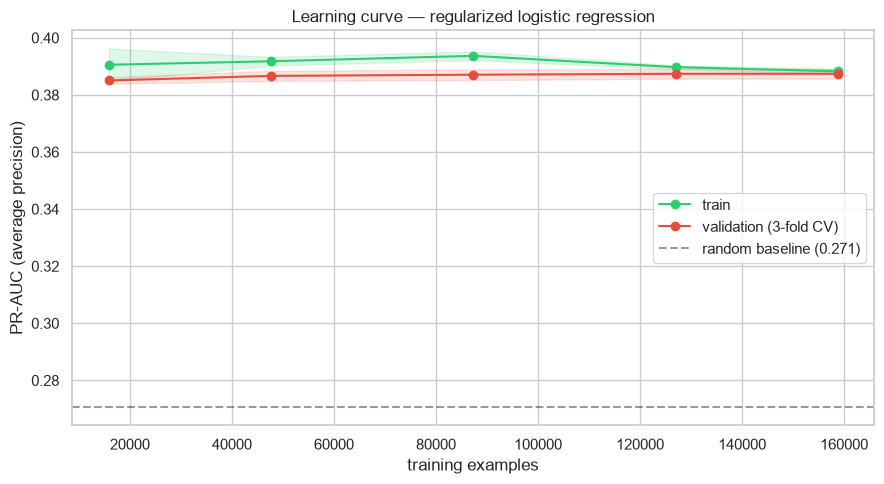

In [8]:
sizes = np.array([0.1, 0.3, 0.55, 0.8, 1.0])
train_sizes, train_scores, cv_scores = learning_curve(
    lr_tuned, X_train_scaled, y_train,
    train_sizes=sizes, cv=cv, scoring="average_precision",
    n_jobs=-1, random_state=RANDOM_STATE,
)

fig, ax = plt.subplots(figsize=(9, 5))
train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
cv_mean, cv_std = cv_scores.mean(axis=1), cv_scores.std(axis=1)

ax.plot(train_sizes, train_mean, "o-", color="#2ecc71", label="train")
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color="#2ecc71")
ax.plot(train_sizes, cv_mean, "o-", color="#e74c3c", label="validation (3-fold CV)")
ax.fill_between(train_sizes, cv_mean - cv_std, cv_mean + cv_std, alpha=0.15, color="#e74c3c")

ax.axhline(y_test.mean(), linestyle="--", color="black", alpha=0.4, label=f"random baseline ({y_test.mean():.3f})")
ax.set_xlabel("training examples")
ax.set_ylabel("PR-AUC (average precision)")
ax.set_title("Learning curve — regularized logistic regression")
ax.legend()
plt.tight_layout()
plt.savefig("../images/13_learning_curve_lr.png", dpi=200, bbox_inches="tight")
plt.show()

Reading the curve: if the two lines sit close together and both plateau, the LR is capacity-limited and the next move is a bigger model class (literally the next section). If there's still a visible gap, the model would benefit from more training data — concretely, dropping the 250k sampling cap in notebook 01 and running on the full ~1.3M completed loans.

## Random forest — a bigger model class, no scaling needed

Trees split on thresholds, so scaled and unscaled features give identical splits. Using the unscaled matrix. Keeping depth modest (10) and estimator count at 200 — enough to see what a forest can do without multiplying runtime unnecessarily.

In [9]:
rf = RandomForestClassifier(
    n_estimators=200, max_depth=10,
    class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=-1,
).fit(X_train, y_train)

rf_metrics = evaluate(rf, X_test, y_test, name="random-forest")
pd.Series(rf_metrics)

name         random-forest
roc_auc           0.699857
pr_auc            0.441487
brier             0.214128
precision         0.402266
recall            0.648607
f1                0.496563
tp                    2095
fp                    3113
tn                    5596
fn                    1135
dtype: object

## XGBoost — gradient-boosted trees, the standard credit-risk workhorse

Boosting adds trees sequentially, each one correcting the previous ensemble's errors. In credit risk it's the de facto workhorse above LR because it handles non-linear interactions, mixed scales and (in principle) missing values natively, and remains fast on tabular data. Using `tree_method='hist'` for speed and `scale_pos_weight = n_negative / n_positive` for class imbalance.

In [10]:
n_neg = int((y_train == 0).sum())
n_pos = int((y_train == 1).sum())

xgb_model = xgb.XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    tree_method="hist",
    scale_pos_weight=n_neg / n_pos,
    eval_metric="logloss",
    random_state=RANDOM_STATE, n_jobs=-1,
).fit(X_train, y_train)

xgb_metrics = evaluate(xgb_model, X_test, y_test, name="xgboost")
pd.Series(xgb_metrics)

name          xgboost
roc_auc      0.708686
pr_auc       0.451944
brier        0.214578
precision    0.412686
recall       0.660681
f1           0.508035
tp               2134
fp               3037
tn               5672
fn               1096
dtype: object

## All models side by side on the 2018 holdout

The number that matters is PR-AUC. Random baseline is just the test-set default rate; anything above that is doing *something* useful.

In [11]:
all_metrics = pd.DataFrame([
    baseline_metrics,
    lr_vanilla_metrics,
    lr_balanced_metrics,
    lr_smote_metrics,
    lr_tuned_metrics,
    rf_metrics,
    xgb_metrics,
])

summary = all_metrics[["name", "roc_auc", "pr_auc", "brier", "precision", "recall", "f1"]].round(4)
print(summary.to_string(index=False))

               name  roc_auc  pr_auc  brier  precision  recall     f1
baseline (majority)   0.5000  0.2705 0.2705     0.0000  0.0000 0.0000
         lr-vanilla   0.6921  0.4225 0.1856     0.5226  0.0929 0.1577
        lr-balanced   0.6914  0.4213 0.2198     0.4067  0.6127 0.4889
           lr-smote   0.6898  0.4199 0.2200     0.4027  0.6099 0.4851
           lr-tuned   0.6914  0.4213 0.2198     0.4067  0.6127 0.4889
      random-forest   0.6999  0.4415 0.2141     0.4023  0.6486 0.4966
            xgboost   0.7087  0.4519 0.2146     0.4127  0.6607 0.5080


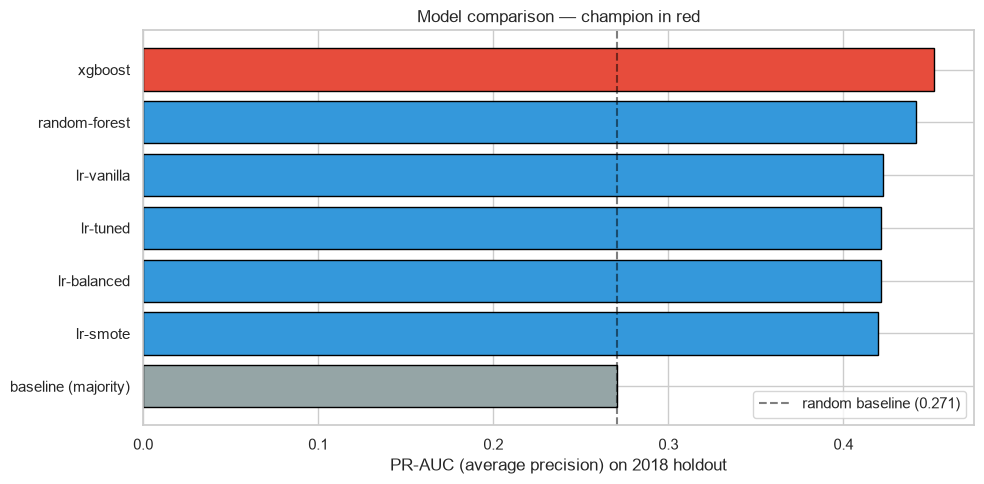

In [12]:
# bar chart of PR-AUC, champion highlighted
sorted_metrics = all_metrics.sort_values("pr_auc").reset_index(drop=True)
champion_name = sorted_metrics.iloc[-1]["name"]

bar_colors = []
for n in sorted_metrics["name"]:
    if n == champion_name:
        bar_colors.append("#e74c3c")
    elif "baseline" in n:
        bar_colors.append("#95a5a6")
    else:
        bar_colors.append("#3498db")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(sorted_metrics["name"], sorted_metrics["pr_auc"], color=bar_colors, edgecolor="black")
ax.axvline(y_test.mean(), linestyle="--", color="black", alpha=0.5,
           label=f"random baseline ({y_test.mean():.3f})")
ax.set_xlabel("PR-AUC (average precision) on 2018 holdout")
ax.set_title("Model comparison — champion in red")
ax.legend()
plt.tight_layout()
plt.savefig("../images/14_model_comparison_pr_auc.png", dpi=200, bbox_inches="tight")
plt.show()

## Is the champion's probability trustworthy? (Calibration)

Ranking loans correctly (good AUC) and reporting trustworthy probabilities (good calibration) are two different things. A model that outputs 0.9 for a bucket of loans that actually default at 60% is well-ranked but miscalibrated — if notebook 05 then multiplies those probabilities by loan amount to compute expected loss, miscalibration misleads the business decision.

Reliability diagram: group test predictions into quantile bins and plot the mean predicted probability against the actual default rate in each bin. A perfectly calibrated model falls on y=x.

champion: xgboost


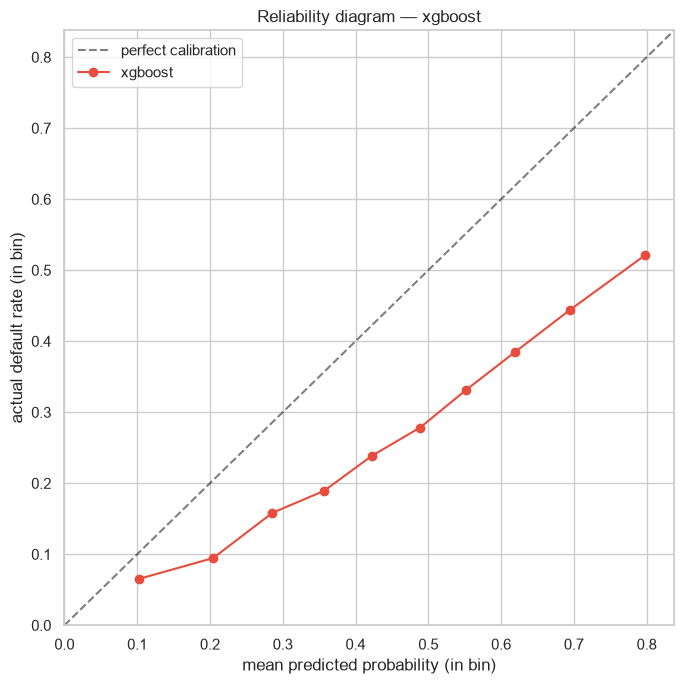

In [13]:
champion_model_map = {
    "baseline (majority)": (baseline, X_test_scaled),
    "lr-vanilla":   (lr_vanilla,  X_test_scaled),
    "lr-balanced":  (lr_balanced, X_test_scaled),
    "lr-smote":     (lr_smote,    X_test_scaled),
    "lr-tuned":     (lr_tuned,    X_test_scaled),
    "random-forest":(rf,          X_test),
    "xgboost":      (xgb_model,   X_test),
}

champion, X_eval = champion_model_map[champion_name]
champion_probs = champion.predict_proba(X_eval)[:, 1]
print(f"champion: {champion_name}")

frac_pos, mean_pred = calibration_curve(y_test, champion_probs, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 1], [0, 1], "--", color="black", alpha=0.5, label="perfect calibration")
ax.plot(mean_pred, frac_pos, "o-", color="#e74c3c", label=champion_name)
ax.set_xlabel("mean predicted probability (in bin)")
ax.set_ylabel("actual default rate (in bin)")
ax.set_title(f"Reliability diagram — {champion_name}")
ax.set_xlim(0, max(mean_pred.max(), frac_pos.max()) * 1.05)
ax.set_ylim(0, max(mean_pred.max(), frac_pos.max()) * 1.05)
ax.legend()
plt.tight_layout()
plt.savefig("../images/15_calibration_champion.png", dpi=200, bbox_inches="tight")
plt.show()

If the champion sits on or near y=x, 05 can take its probabilities at face value when computing expected loss. If it's systematically above or below the diagonal, 05 will need to either Platt-scale / isotonic-calibrate the output, or just rank-order loans and pick an operational cutoff on empirical defaults rather than on predicted probability.

## Saving the champion and test predictions for notebook 05

Three files land:

- `models/best_model.joblib` — the fitted champion, plus the kind of input it expects (scaled vs unscaled).
- `data/processed/test_predictions.csv` — one row per test loan with target, predicted probability, and loan amount. 05 needs loan amount to compute expected loss.
- `data/processed/model_metrics.json` — the full comparison table in machine-readable form so I can quote it in the README without transcribing anything by hand.

In [14]:
models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)

joblib.dump(
    {
        "name": champion_name,
        "model": champion,
        "input": "scaled" if champion_name.startswith("lr") or champion_name == "baseline (majority)" else "unscaled",
    },
    models_dir / "best_model.joblib",
    compress=3,
)

# align loan_amnt with the test rows (same filter as 03's split)
cleaned = pd.read_csv(
    "../data/processed/loan_cleaned.csv",
    parse_dates=["issue_d_dt"],
)
test_cleaned = (
    cleaned[cleaned["issue_d_dt"] >= pd.Timestamp("2018-01-01")]
    .reset_index(drop=True)
)
assert len(test_cleaned) == len(y_test), f"size mismatch {len(test_cleaned)} vs {len(y_test)}"

preds = pd.DataFrame({
    "target":     y_test.values,
    "pred_prob":  champion_probs,
    "loan_amnt":  test_cleaned["loan_amnt"].values,
    "int_rate":   test_cleaned["int_rate"].values,
    "term":       test_cleaned["term"].values,
})
preds.to_csv("../data/processed/test_predictions.csv", index=False)

with open("../data/processed/model_metrics.json", "w") as f:
    json.dump({
        "champion": champion_name,
        "test_default_rate": float(y_test.mean()),
        "test_size": int(len(y_test)),
        "train_size": int(len(y_train)),
        "models": summary.to_dict(orient="records"),
    }, f, indent=2)

print(f"saved champion: {champion_name}")
print(f"saved {len(preds):,} test predictions to data/processed/test_predictions.csv")
print(f"saved metrics table to data/processed/model_metrics.json")

saved champion: xgboost
saved 11,939 test predictions to data/processed/test_predictions.csv
saved metrics table to data/processed/model_metrics.json


## What I'm taking away

**Learning curves changed how I'd argue for the next step.** Before computing them I had a vague belief that "more data would help." The curve tells me whether that's actually true — if train and validation sit close together and plateau, no amount of extra Lending Club loans will push the LR above its current PR-AUC and I need a different model class. If there's an open gap, dropping the sampling cap in notebook 01 would be the first thing to try. Having that diagnostic distinction concrete (rather than "I feel like we should try X") is the specific thing Andrew's bias/variance lecture was about and I think I finally get it.

**One honest limitation.** Everything above is validated on a single 2018 holdout, which is a small window and introduces real variance into the model-vs-model comparison. The gap between any two models here might be smaller than it looks under resampling. A proper evaluation would be a rolling-origin backtest: train on 2007–2014, test on 2015; train on 2007–2015, test on 2016; and so on, averaging across folds. For a portfolio project a single-window holdout is the standard shortcut, but it's a shortcut.

**One thing I'd do differently next time.** I only ran a learning curve for the LR. For a complete bias/variance picture I'd do the same for RF and XGBoost — each has different signatures (tree ensembles tend to show much wider train-validation gaps than LR, which is informative in its own right). I didn't do it in this notebook mostly because of runtime, but on a cleaner iteration it belongs here.

**Where notebook 05 picks up.** The champion's raw probabilities on the test set are now the input to a cost-sensitive decision: at what probability do I reject a loan? That isn't a classifier-accuracy question; it's an expected-loss question that depends on loan amount, loss-given-default, and the lost interest income from false rejections. That's the whole of notebook 05.